KAN (RBF) run 5/5: 100%|██████████| 15000/15000 [00:11<00:00, 1272.59it/s, loss=0.0004]


saved results\test5_square_wave.png
saved results\test5_square_wave.pdf


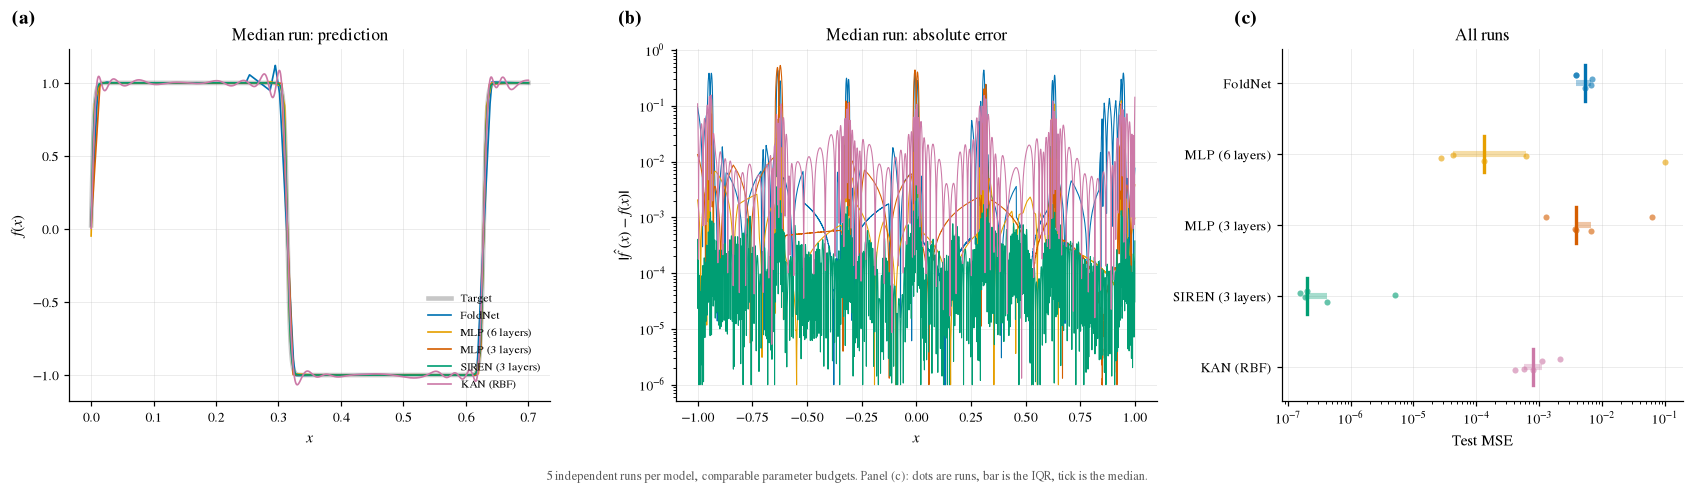

| Model | Params | Test MSE | Max abs. error | Relative $L^2$ error | P(FoldNet better) | p-value |
|---|---|---|---|---|---|---|
| FoldNet | 673 | 5.44e-03 [3.85e-03, 6.83e-03] | 0.440 [0.404, 0.456] | 0.075 [0.063, 0.084] | - | - |
| MLP (6 layers) | 694 | 1.35e-04 [4.26e-05, 6.23e-04] | 0.143 [0.068, 0.351] | 0.012 [0.007, 0.025] | 0.20 | n/a |
| MLP (3 layers) | 664 | 3.91e-03 [3.76e-03, 6.61e-03] | 0.533 [0.526, 0.637] | 0.064 [0.062, 0.083] | 0.40 | n/a |
| SIREN (3 layers) | 664 | **2.05e-07 [1.88e-07, 4.22e-07]** | 0.006 [0.004, 0.007] | 0.000 [0.000, 0.001] | 0.00 | n/a |
| KAN (RBF) | 673 | 8.06e-04 [5.77e-04, 1.10e-03] | 0.201 [0.158, 0.213] | 0.029 [0.024, 0.034] | 0.00 | n/a |
saved results\test5_square_wave_table.{md,tex,csv}


In [1]:
"""Test 5: sharp square-like wave tanh(20 sin(10x)). Multi-run, five models."""
import numpy as np
import torch
import matplotlib.pyplot as plt

from foldnet_bench import standard_builders, benchmark
import foldnet_viz as V

N_RUNS = 5
STEPS = 15000
D, DEPTH, K = 32, 6, 2
ZOOM = (0.0, 0.7)
RESULTS_DIR = "results"


def f(x):
    return torch.tanh(20 * torch.sin(10 * x))


if __name__ == "__main__":
    V.set_style()
    builders, target = standard_builders(1, 1, D, DEPTH, K)
    names = list(builders)
    res, xs, ys = benchmark(builders, f, n_runs=N_RUNS, steps=STEPS)

    mse = {n: np.array([r["mse"] for r in res[n]]) for n in names}
    mxe = {n: np.array([r["max_err"] for r in res[n]]) for n in names}
    rel = {n: np.array([r["rel_l2"] for r in res[n]]) for n in names}
    npar = {n: res[n][0]["n_params"] for n in names}
    med_run = {n: res[n][int(np.argsort(mse[n])[N_RUNS // 2])] for n in names}

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3), gridspec_kw=dict(width_ratios=[1.2, 1.2, 1]))
    mask = (xs >= ZOOM[0]) & (xs <= ZOOM[1])
    ax = axes[0]
    ax.plot(xs[mask], ys[mask], color=V.COLORS["Target"], lw=3.0, alpha=0.25, label="Target")
    for n in names:
        ax.plot(xs[mask], med_run[n]["pred"][mask], color=V.color_for(n), lw=1.1, label=n)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$f(x)$")
    ax.set_title("Median run: prediction")
    ax.legend(fontsize=7.5, loc="lower right")
    V.panel_label(ax, "(a)")

    ax = axes[1]
    for n in names:
        err = np.maximum(np.abs(med_run[n]["pred"] - ys), 1e-6)
        ax.plot(xs, err, color=V.color_for(n), lw=0.7, label=n)
    ax.set_yscale("log")
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$|\hat f(x) - f(x)|$")
    ax.set_title("Median run: absolute error")
    V.panel_label(ax, "(b)")

    ax = axes[2]
    V.strip(ax, names, [mse[n] for n in names], {n: V.color_for(n) for n in names},
            horizontal=True)
    ax.set_xscale("log")
    ax.set_xlabel("Test MSE")
    ax.set_title("All runs")
    V.panel_label(ax, "(c)")

    fig.text(0.5, -0.03, f"{N_RUNS} independent runs per model, comparable parameter budgets. "
             "Panel (c): dots are runs, bar is the IQR, tick is the median.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test5_square_wave", RESULTS_DIR)
    plt.show()

    tab = V.Table(["Model", "Params", "Test MSE", "Max abs. error", "Relative $L^2$ error",
                   "P(FoldNet better)", "p-value"])
    best = min(names, key=lambda n: np.median(mse[n]))
    for n in names:
        pb, pv = ("-", "-") if n == "FoldNet" else V.vs_ref(mse["FoldNet"], mse[n])
        tab.add(n, npar[n], V.med_iqr(mse[n]), V.med_iqr(mxe[n], lambda v: f"{v:.3f}"),
                V.med_iqr(rel[n], lambda v: f"{v:.3f}"), pb, pv, bold={2} if n == best else ())
    tab.show()
    tab.save("test5_square_wave_table", RESULTS_DIR,
             caption=(f"Regression of $\\tanh(20\\sin(10x))$ ({N_RUNS} runs), median [Q1, Q3]. "
                      "P(FoldNet better) is computed on the test MSE. Bold: best median."),
             label="tab:square")